In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import numpy as np
import random
import gymnasium as gym
import matplotlib.pyplot as plt

from collections import deque
from pathlib import Path


In [4]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, action_dim)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

In [6]:
SEED = 42

NUM_EPISODES = 3000
MAX_STEPS = 500

GAMMA = 0.99
LEARNING_RATE = 0.001
BATCH_SIZE = 64
BUFFER_SIZE = 100000

EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY_STEPS = 50000

TARGET_UPDATE_FREQ = 1000

MIN_POLE_LENGTH = 0.4
MAX_POLE_LENGTH = 1.8
LAMBDA_SYM = 0.1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [8]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((
            state,
            action,
            reward,
            next_state,
            done
        ))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)

        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.tensor(
            np.array(states), dtype=torch.float32, device=device
        )
        actions = torch.tensor(
            actions, dtype=torch.long, device=device
        ).unsqueeze(1)
        rewards = torch.tensor(
            rewards, dtype=torch.float32, device=device
        )
        next_states = torch.tensor(
            np.array(next_states), dtype=torch.float32, device=device
        )
        dones = torch.tensor(
            dones, dtype=torch.float32, device=device
        )

        return states, actions, rewards, next_states, dones

    def __len__(self):
        return len(self.buffer)

In [10]:
def get_epsilon(step):
    fraction = min(step / EPSILON_DECAY_STEPS, 1.0)

    return EPSILON_START + fraction * (
        EPSILON_END - EPSILON_START
    )


def select_action(state, policy_net, epsilon):
    if random.random() < epsilon:
        return random.randrange(2)

    state_tensor = torch.tensor(
        state, dtype=torch.float32, device=device
    ).unsqueeze(0)

    with torch.no_grad():
        q_values = policy_net(state_tensor)

    return q_values.argmax(dim=1).item()

In [12]:
def update_dqn(policy_net, target_net, optimizer, replay_buffer):

    if len(replay_buffer) < BATCH_SIZE:
        return None

    states, actions, rewards, next_states, dones = (
        replay_buffer.sample(BATCH_SIZE)
    )

    # 1. Standard DQN loss
    q_values = policy_net(states)
    current_q = q_values.gather(1, actions).squeeze(1)

    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1).values
        target_q = rewards + GAMMA * (1 - dones) * next_q

    dqn_loss = F.mse_loss(current_q, target_q)

    # 2. Create mirrored states
    # State: [cart position, cart velocity, pole angle, angular velocity]
    mirrored_states = -states

    # 3. Predict Q-values for mirrored states
    mirrored_q_values = policy_net(mirrored_states)

    # 4. Swap action values: left <-> right
    mirrored_q_swapped = mirrored_q_values[:, [1, 0]]

    # 5. Symmetry regularization loss
    symmetry_loss = F.mse_loss(q_values, mirrored_q_swapped)

    # 6. Combined loss
    total_loss = dqn_loss + LAMBDA_SYM * symmetry_loss

    # 7. Update network
    optimizer.zero_grad()
    total_loss.backward()
    optimizer.step()

    return total_loss.item()

In [14]:
def train_baseline():

    env = gym.make("CartPole-v1")

    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    policy_net = QNetwork(state_dim, action_dim).to(device)
    target_net = QNetwork(state_dim, action_dim).to(device)

    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(
        policy_net.parameters(),
        lr=LEARNING_RATE
    )

    replay_buffer = ReplayBuffer(BUFFER_SIZE)

    episode_rewards = []
    losses = []
    total_steps = 0

    for episode in range(NUM_EPISODES):

        # Sample a new pole length each episode
        length = np.random.uniform(
            MIN_POLE_LENGTH, MAX_POLE_LENGTH
        )

        env.unwrapped.length = length

        state, info = env.reset()
        episode_reward = 0

        for step in range(MAX_STEPS):

            epsilon = get_epsilon(total_steps)

            action = select_action(
                state, policy_net, epsilon
            )

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            done = terminated or truncated

            # Store transition.
            # Only true termination removes future value from TD target.
            replay_buffer.push(
                state,
                action,
                reward,
                next_state,
                terminated
            )

            loss = update_dqn(
                policy_net,
                target_net,
                optimizer,
                replay_buffer
            )

            if loss is not None:
                losses.append(loss)

            state = next_state
            episode_reward += reward
            total_steps += 1

            # Update target network
            if total_steps % TARGET_UPDATE_FREQ == 0:
                target_net.load_state_dict(
                    policy_net.state_dict()
                )

            if done:
                break

        episode_rewards.append(episode_reward)

        if (episode + 1) % 100 == 0:
            avg_reward = np.mean(episode_rewards[-100:])

            print(
                f"Episode {episode + 1}/{NUM_EPISODES} | "
                f"Avg reward: {avg_reward:.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    return policy_net, episode_rewards, losses

In [16]:
symmetry_model, rewards, losses = train_baseline()

Episode 100/3000 | Avg reward: 35.16 | Epsilon: 0.933
Episode 200/3000 | Avg reward: 33.85 | Epsilon: 0.869
Episode 300/3000 | Avg reward: 53.06 | Epsilon: 0.768
Episode 400/3000 | Avg reward: 53.88 | Epsilon: 0.666
Episode 500/3000 | Avg reward: 60.23 | Epsilon: 0.551
Episode 600/3000 | Avg reward: 93.59 | Epsilon: 0.373
Episode 700/3000 | Avg reward: 123.35 | Epsilon: 0.139
Episode 800/3000 | Avg reward: 154.78 | Epsilon: 0.050
Episode 900/3000 | Avg reward: 307.48 | Epsilon: 0.050
Episode 1000/3000 | Avg reward: 409.88 | Epsilon: 0.050
Episode 1100/3000 | Avg reward: 433.79 | Epsilon: 0.050
Episode 1200/3000 | Avg reward: 418.17 | Epsilon: 0.050
Episode 1300/3000 | Avg reward: 432.59 | Epsilon: 0.050
Episode 1400/3000 | Avg reward: 368.74 | Epsilon: 0.050
Episode 1500/3000 | Avg reward: 350.84 | Epsilon: 0.050
Episode 1600/3000 | Avg reward: 436.73 | Epsilon: 0.050
Episode 1700/3000 | Avg reward: 416.83 | Epsilon: 0.050
Episode 1800/3000 | Avg reward: 395.37 | Epsilon: 0.050
Episode

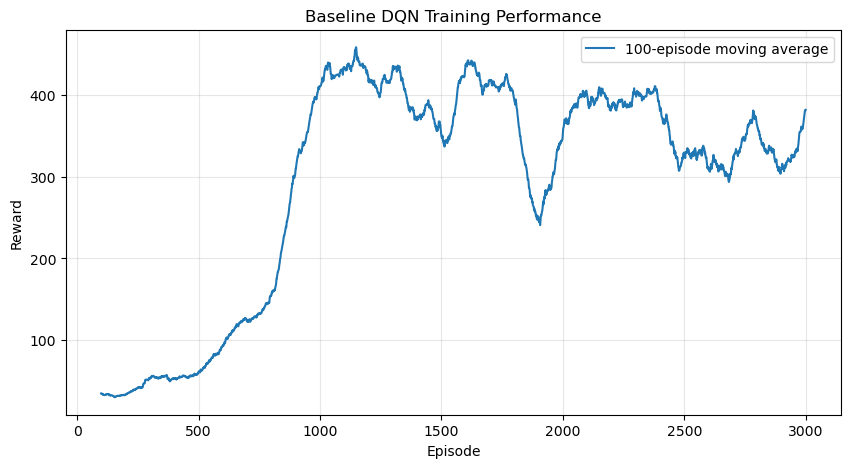

In [18]:
plt.figure(figsize=(10, 5))

moving_average = (
    np.convolve(rewards, np.ones(100) / 100, mode="valid")
)

plt.plot(
    np.arange(99, len(rewards)),
    moving_average,
    label="100-episode moving average"
)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Baseline DQN Training Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [20]:
from pathlib import Path

Path("weights").mkdir(exist_ok=True)

torch.save(
    symmetry_model.cpu().state_dict(),
    "weights/symmetry.pth"
)

print("Saved weights/symmetry.pth")

Saved weights/symmetry.pth
